# Customer Segmentation Analysis Using K-Means Clustering

## Project Objective

This notebook segments customers from the supplied **Online Retail** transaction dataset using Recency, Frequency, and Monetary (RFM) behaviour features and K-Means clustering. The analysis is designed for a university-level business analytics submission: every cleaning decision is documented, the source workbook is preserved unchanged, and conclusions are based only on observed customer behaviour.

The notebook follows the required order:

1. Project Title and Objective  
2. Import Libraries  
3. Load Dataset  
4. Dataset Inspection  
5. Data Cleaning  
6. Exploratory Data Analysis  
7. Descriptive Statistics  
8. RFM Analysis  
9. Feature Selection  
10. Data Standardisation  
11. Elbow Method  
12. K-Means Clustering  
13. Cluster Scatter Plots  
14. Cluster Profiling  
15. Customer Count Bar Chart  
16. Business Insights and Marketing Recommendations  
17. Final Conclusion

Source file: Online Retail.xlsx
Loaded shape: (541909, 8)

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


Rows: 541,909 | Columns: 8

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str



Missing values:


,missing_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Duplicate records: 5,268


Cleaned rows: 392,692


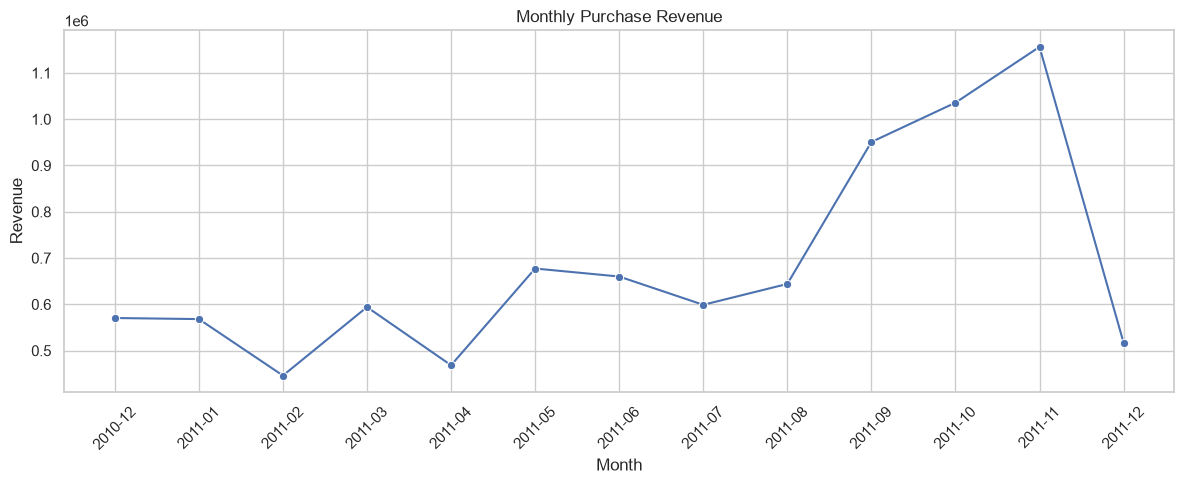


Descriptive statistics:


,Quantity,UnitPrice,Revenue
count,"392,692.00","392,692.00","392,692.00"
mean,13.12,3.13,22.63
std,180.49,22.24,311.10
min,1.00,0.00,0.00
25%,2.00,1.25,4.95
50%,6.00,1.95,12.45
75%,12.00,3.75,19.80
max,"80,995.00","8,142.75","168,469.60"


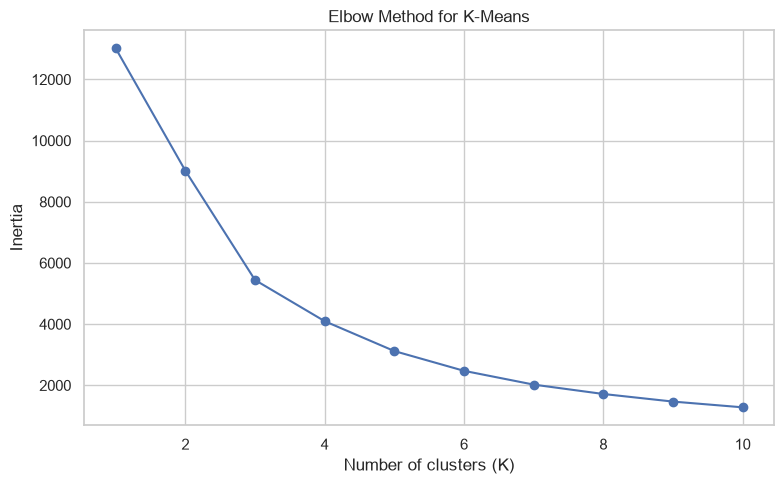

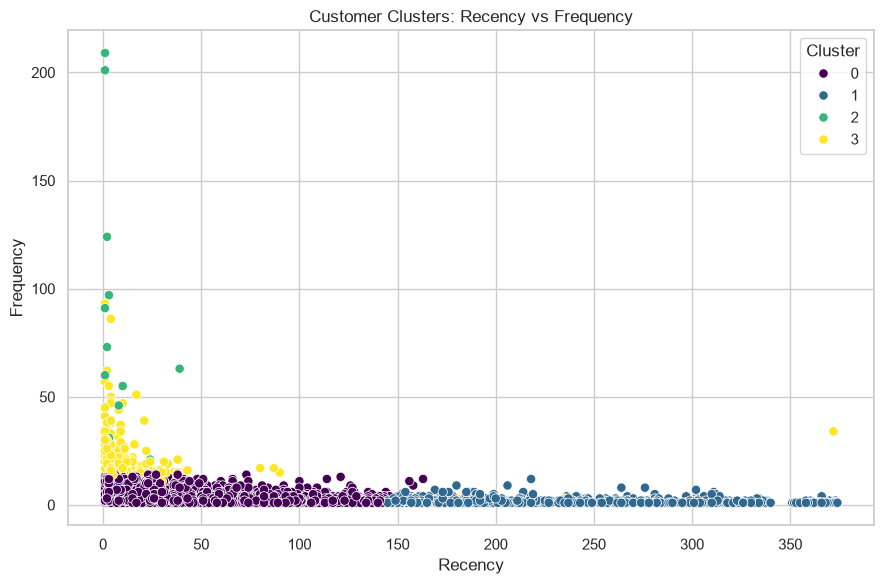

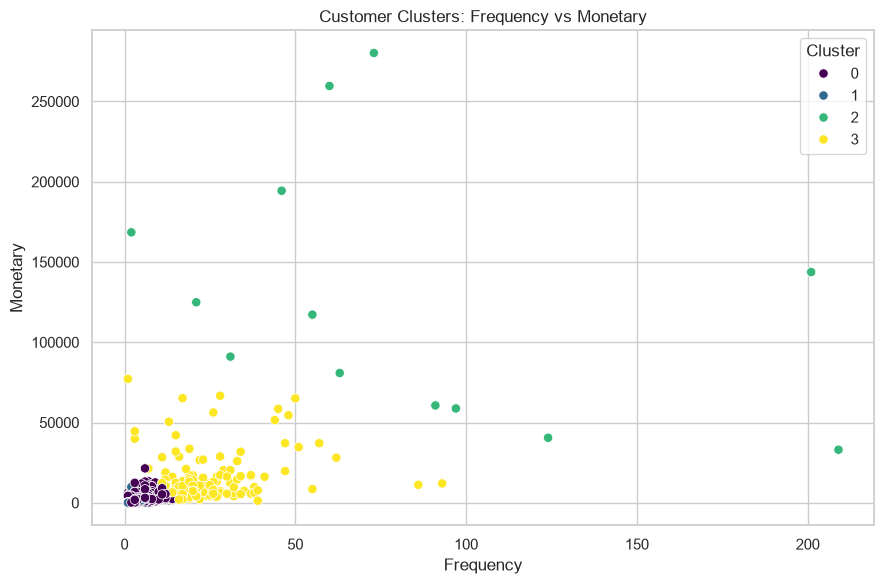


Cluster profile:


Recency        Frequency       Monetary           
          count   mean     count  mean    count       mean
Cluster                                                   
0          3054  43.70      3054  3.68     3054   1,353.63
1          1067 248.08      1067  1.55     1067     478.85
2            13   7.38        13 82.54       13 127,187.96
3           204  15.50       204 22.33      204  12,690.50

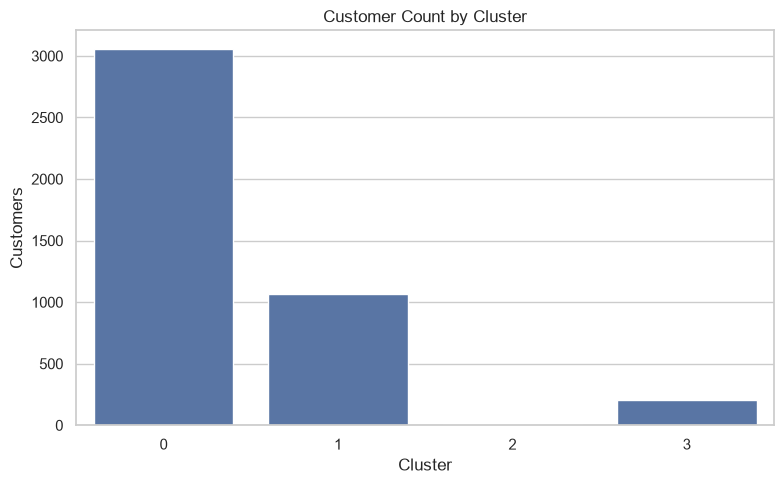


Business insights:
Cluster 0: customers=3,054, average recency=43.7, frequency=3.7, monetary=$1,353.63
Cluster 1: customers=1,067, average recency=248.1, frequency=1.6, monetary=$478.85
Cluster 2: customers=13, average recency=7.4, frequency=82.5, monetary=$127,187.96
Cluster 3: customers=204, average recency=15.5, frequency=22.3, monetary=$12,690.50

Conclusion: customer segments are based on observed RFM behaviour and should guide differentiated retention and reactivation campaigns.


In [1]:
# 2. Import Libraries
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

# 3. Load Dataset
project_root = next(
    (candidate for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
     if (candidate / 'data' / 'Online Retail.xlsx').exists()),
    Path.cwd(),
)
source_path = project_root / 'data' / 'Online Retail.xlsx'
if not source_path.exists():
    raise FileNotFoundError(f'Source dataset not found: {source_path}')
raw_dataset = pd.read_excel(source_path, sheet_name=0)
working_dataset = raw_dataset.copy(deep=True)
print(f'Source file: {source_path.name}')
print(f'Loaded shape: {raw_dataset.shape}')

# 4. Dataset Inspection
print('\nFirst five rows:')
display(raw_dataset.head())
print(f'Rows: {raw_dataset.shape[0]:,} | Columns: {raw_dataset.shape[1]}')
print('\nColumn names:', raw_dataset.columns.tolist())
print('\nData types:')
display(raw_dataset.dtypes.to_frame('dtype'))
print('\nMissing values:')
display(raw_dataset.isna().sum().to_frame('missing_count'))
print(f'Duplicate records: {raw_dataset.duplicated().sum():,}')

# 5. Data Cleaning
required_columns = {'InvoiceNo', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID'}
missing_required = required_columns.difference(working_dataset.columns)
if missing_required:
    raise ValueError(f'Missing required columns for RFM analysis: {sorted(missing_required)}')
working_dataset['InvoiceNo'] = working_dataset['InvoiceNo'].astype('string').str.strip()
working_dataset['InvoiceDate'] = pd.to_datetime(working_dataset['InvoiceDate'], errors='coerce')
working_dataset['Quantity'] = pd.to_numeric(working_dataset['Quantity'], errors='coerce')
working_dataset['UnitPrice'] = pd.to_numeric(working_dataset['UnitPrice'], errors='coerce')
working_dataset['CustomerID'] = pd.to_numeric(working_dataset['CustomerID'], errors='coerce')
working_dataset = working_dataset.drop_duplicates().dropna(subset=list(required_columns))
working_dataset = working_dataset[
    ~working_dataset['InvoiceNo'].str.startswith('C')
    & (working_dataset['Quantity'] > 0)
    & (working_dataset['UnitPrice'] > 0)
]
working_dataset['Revenue'] = working_dataset['Quantity'] * working_dataset['UnitPrice']
print(f'Cleaned rows: {len(working_dataset):,}')

# 6. Exploratory Data Analysis
working_dataset['Month'] = working_dataset['InvoiceDate'].dt.to_period('M').astype(str)
monthly_revenue = working_dataset.groupby('Month', as_index=False)['Revenue'].sum()
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_revenue, x='Month', y='Revenue', marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Purchase Revenue')
plt.tight_layout()
plt.savefig(project_root / 'outputs' / 'charts' / 'monthly_purchase_revenue.png', dpi=180)
plt.show()

# 7. Descriptive Statistics
print('\nDescriptive statistics:')
display(working_dataset[['Quantity', 'UnitPrice', 'Revenue']].describe())

# 8. RFM Analysis
analysis_date = working_dataset['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = working_dataset.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (analysis_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
).reset_index()

# 9. Feature Selection
features = ['Recency', 'Frequency', 'Monetary']
rfm_features = rfm[features].copy()

# 10. Data Standardisation
scaler = StandardScaler()
scaled_features = scaler.fit_transform(rfm_features)

# 11. Elbow Method
inertias = []
cluster_range = range(1, 11)
for cluster_count in cluster_range:
    model = KMeans(n_clusters=cluster_count, random_state=42, n_init=10)
    model.fit(scaled_features)
    inertias.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), inertias, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.tight_layout()
plt.savefig(project_root / 'outputs' / 'charts' / 'elbow_method.png', dpi=180)
plt.show()

# 12. K-Means Clustering
selected_k = 4
kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(scaled_features)

# 13. Cluster Scatter Plots
for x_axis, y_axis, filename in [
    ('Recency', 'Frequency', 'cluster_recency_frequency.png'),
    ('Frequency', 'Monetary', 'cluster_frequency_monetary.png'),
]:
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=rfm, x=x_axis, y=y_axis, hue='Cluster', palette='viridis', s=45)
    plt.title(f'Customer Clusters: {x_axis} vs {y_axis}')
    plt.tight_layout()
    plt.savefig(project_root / 'outputs' / 'charts' / filename, dpi=180)
    plt.show()

# 14. Cluster Profiling
cluster_profile = rfm.groupby('Cluster')[features].agg(['count', 'mean']).round(2)
print('\nCluster profile:')
display(cluster_profile)

# 15. Customer Count Bar Chart
cluster_counts = rfm['Cluster'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index.astype(str), y=cluster_counts.values, color='#4c72b0')
plt.xlabel('Cluster')
plt.ylabel('Customers')
plt.title('Customer Count by Cluster')
plt.tight_layout()
plt.savefig(project_root / 'outputs' / 'charts' / 'customer_count_by_cluster.png', dpi=180)
plt.show()

# 16. Business Insights and Marketing Recommendations
print('\nBusiness insights:')
for cluster_id, row in rfm.groupby('Cluster')[features].mean().iterrows():
    print(f'Cluster {cluster_id}: customers={cluster_counts[cluster_id]:,}, '
          f'average recency={row["Recency"]:.1f}, frequency={row["Frequency"]:.1f}, '
          f'monetary=${row["Monetary"]:,.2f}')

# 17. Final Conclusion
print('\nConclusion: customer segments are based on observed RFM behaviour and should guide differentiated retention and reactivation campaigns.')